In [1]:
import os
os.environ["PYTHONWARNINGS"] = "ignore"

In [2]:
import warnings
warnings.filterwarnings("ignore")

In [3]:
import random
import numpy as np
import scanpy as sc
import squidpy as sq
import torch
import spice

In [4]:
sc.set_figure_params(frameon=False)
sc.settings._vector_friendly = False

In [5]:
def set_seeds(seed: int) -> None:
    """Seed all random-state sources for fully reproducible GNN training.

    Covers: Python random, NumPy global state, PyTorch CPU/CUDA, and
    cuDNN determinism flags.  Call once at notebook start and once per
    simulation iteration to reset the state before each training run.
    """
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

In [6]:
from simulate_xenium import simulate_xenium

## Run SPiCe

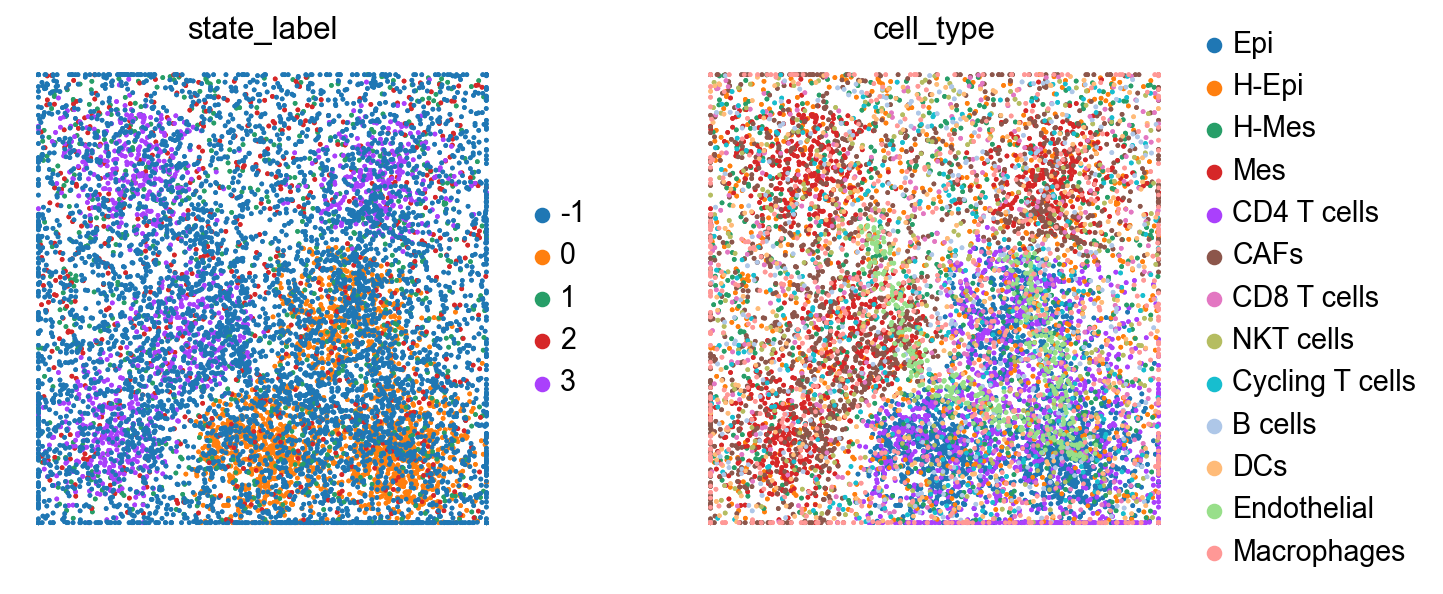

In [7]:
EMT_MAP = {"0": "Epi", "1": "H-Epi", "2": "H-Mes", "3": "Mes"}

all_aucs = []

random.seed(0)

seed = 10518
adata, _ = simulate_xenium(seed=seed)

valid_states = {
    "Epi": 0,
    "H-Epi": 1,
    "H-Mes": 2,
    "Mes": 3,
}

adata.obs["state_label"] = (adata.obs["cell_type"].map(valid_states).fillna(-1).astype(int))
adata.obs["state_label"] = adata.obs["state_label"].astype("category")
adata.obs["state_label"] = adata.obs["state_label"].cat.remove_unused_categories()

sq.pl.spatial_scatter(
    adata,
    color=["state_label", "cell_type"],
    save=f"simulation_{seed}_spatial.pdf",
    shape=None,
    size=5
)


Fold 1/5


  Epoch    0 | Loss 0.3097 | Test AUC: 0.6310


  Epoch  100 | Loss 0.2273 | Test AUC: 0.7745


  Epoch  200 | Loss 0.2206 | Test AUC: 0.7902


  Epoch  300 | Loss 0.2197 | Test AUC: 0.7909


  Epoch  400 | Loss 0.2181 | Test AUC: 0.7903


... (111 outputs left out)

findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


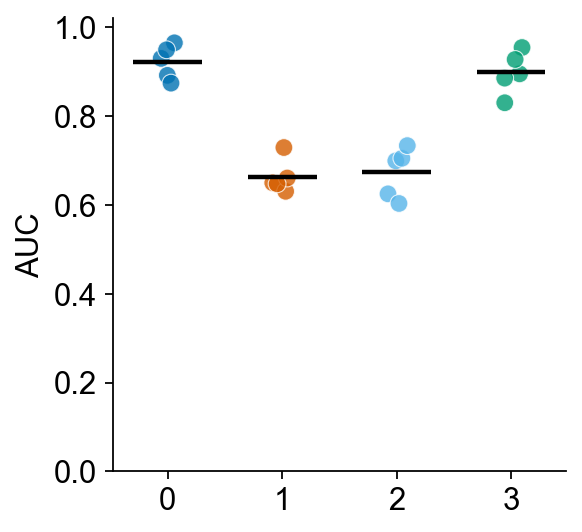

In [8]:
EMT_MAP = {0: "Epi", 1: "H-Epi", 2: "H-Mes", 3: "Mes"}
spice.tl.build_graph(
    adata,
    celltype_key="celltype_minor",
    label_key="state_label",
    score_key=None,
    n_blocks=8
)

spice.tl.cross_validate(adata, feature_mode="celltype")
spice.tl.evaluate(adata)
spice.pl.auc_per_class(adata, state_map=EMT_MAP, save=f"figures/simulation_{seed}_auc_per_class_hallmark.pdf")

In [9]:
import numpy as np
import pandas as pd
from scipy.special import softmax

# initialise column
adata.obs["spice_emt_score"] = np.nan

# extract results
predicted = adata.uns["spice"]["cv_results"]["all_predicted"]
folds = adata.uns["spice"]["folds"]

for preds, fold in zip(predicted, folds):
    # convert logits to probabilities
    probs = softmax(preds, axis=1)

    # expected class score (continuous 0-3)
    classes = np.arange(probs.shape[1])
    continuous_score = (probs * classes).sum(axis=1)

    # obtain test cells for this fold
    test_mask = fold.test_mask.cpu().numpy()

    if hasattr(fold.cell_id, "cpu"):
        cell_ids = np.array(fold.cell_id.cpu())
    else:
        cell_ids = np.array(fold.cell_id)

    test_cells = cell_ids[test_mask]

    # store scores
    adata.obs.loc[test_cells, "spice_emt_score"] = continuous_score

# check assignment
print(f"Assigned scores to {adata.obs['spice_emt_score'].notna().sum()} cells")

Assigned scores to 4121 cells


findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


... (56 outputs left out)

findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


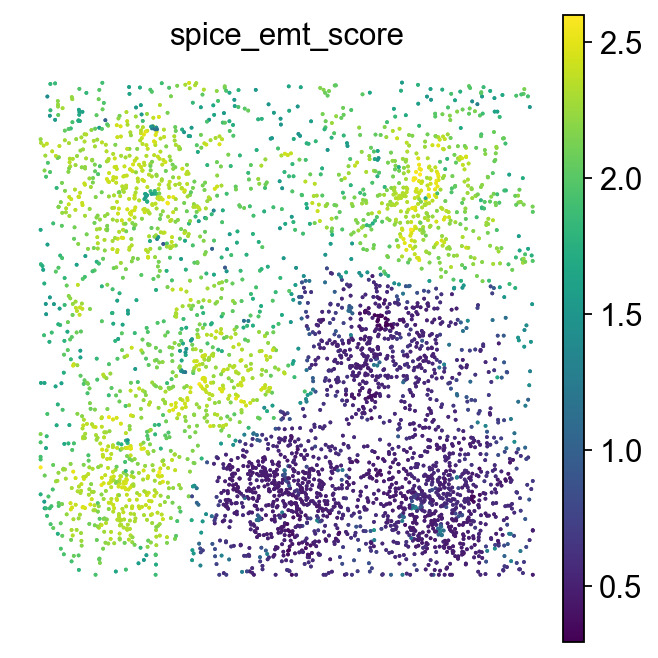

In [10]:
# plot
sq.pl.spatial_scatter(
    adata,
    color="spice_emt_score",
    cmap="viridis",
    shape=None,
    size=2,
    save=f"simulation_{seed}_spice_emt_pred_spatial.pdf",
)

Computing node explanations for label 0...


Label 0:   0%|          | 0/240 [00:00<?, ?it/s]

Label 0:   0%|          | 1/240 [00:01<05:25,  1.36s/it]

Label 0:   1%|          | 2/240 [00:02<05:28,  1.38s/it]

Label 0:   1%|▏         | 3/240 [00:04<05:25,  1.37s/it]

Label 0:   2%|▏         | 4/240 [00:06<07:35,  1.93s/it]

... (4,454 outputs left out)

findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


findfont: Font family 'Helvetica' not found.


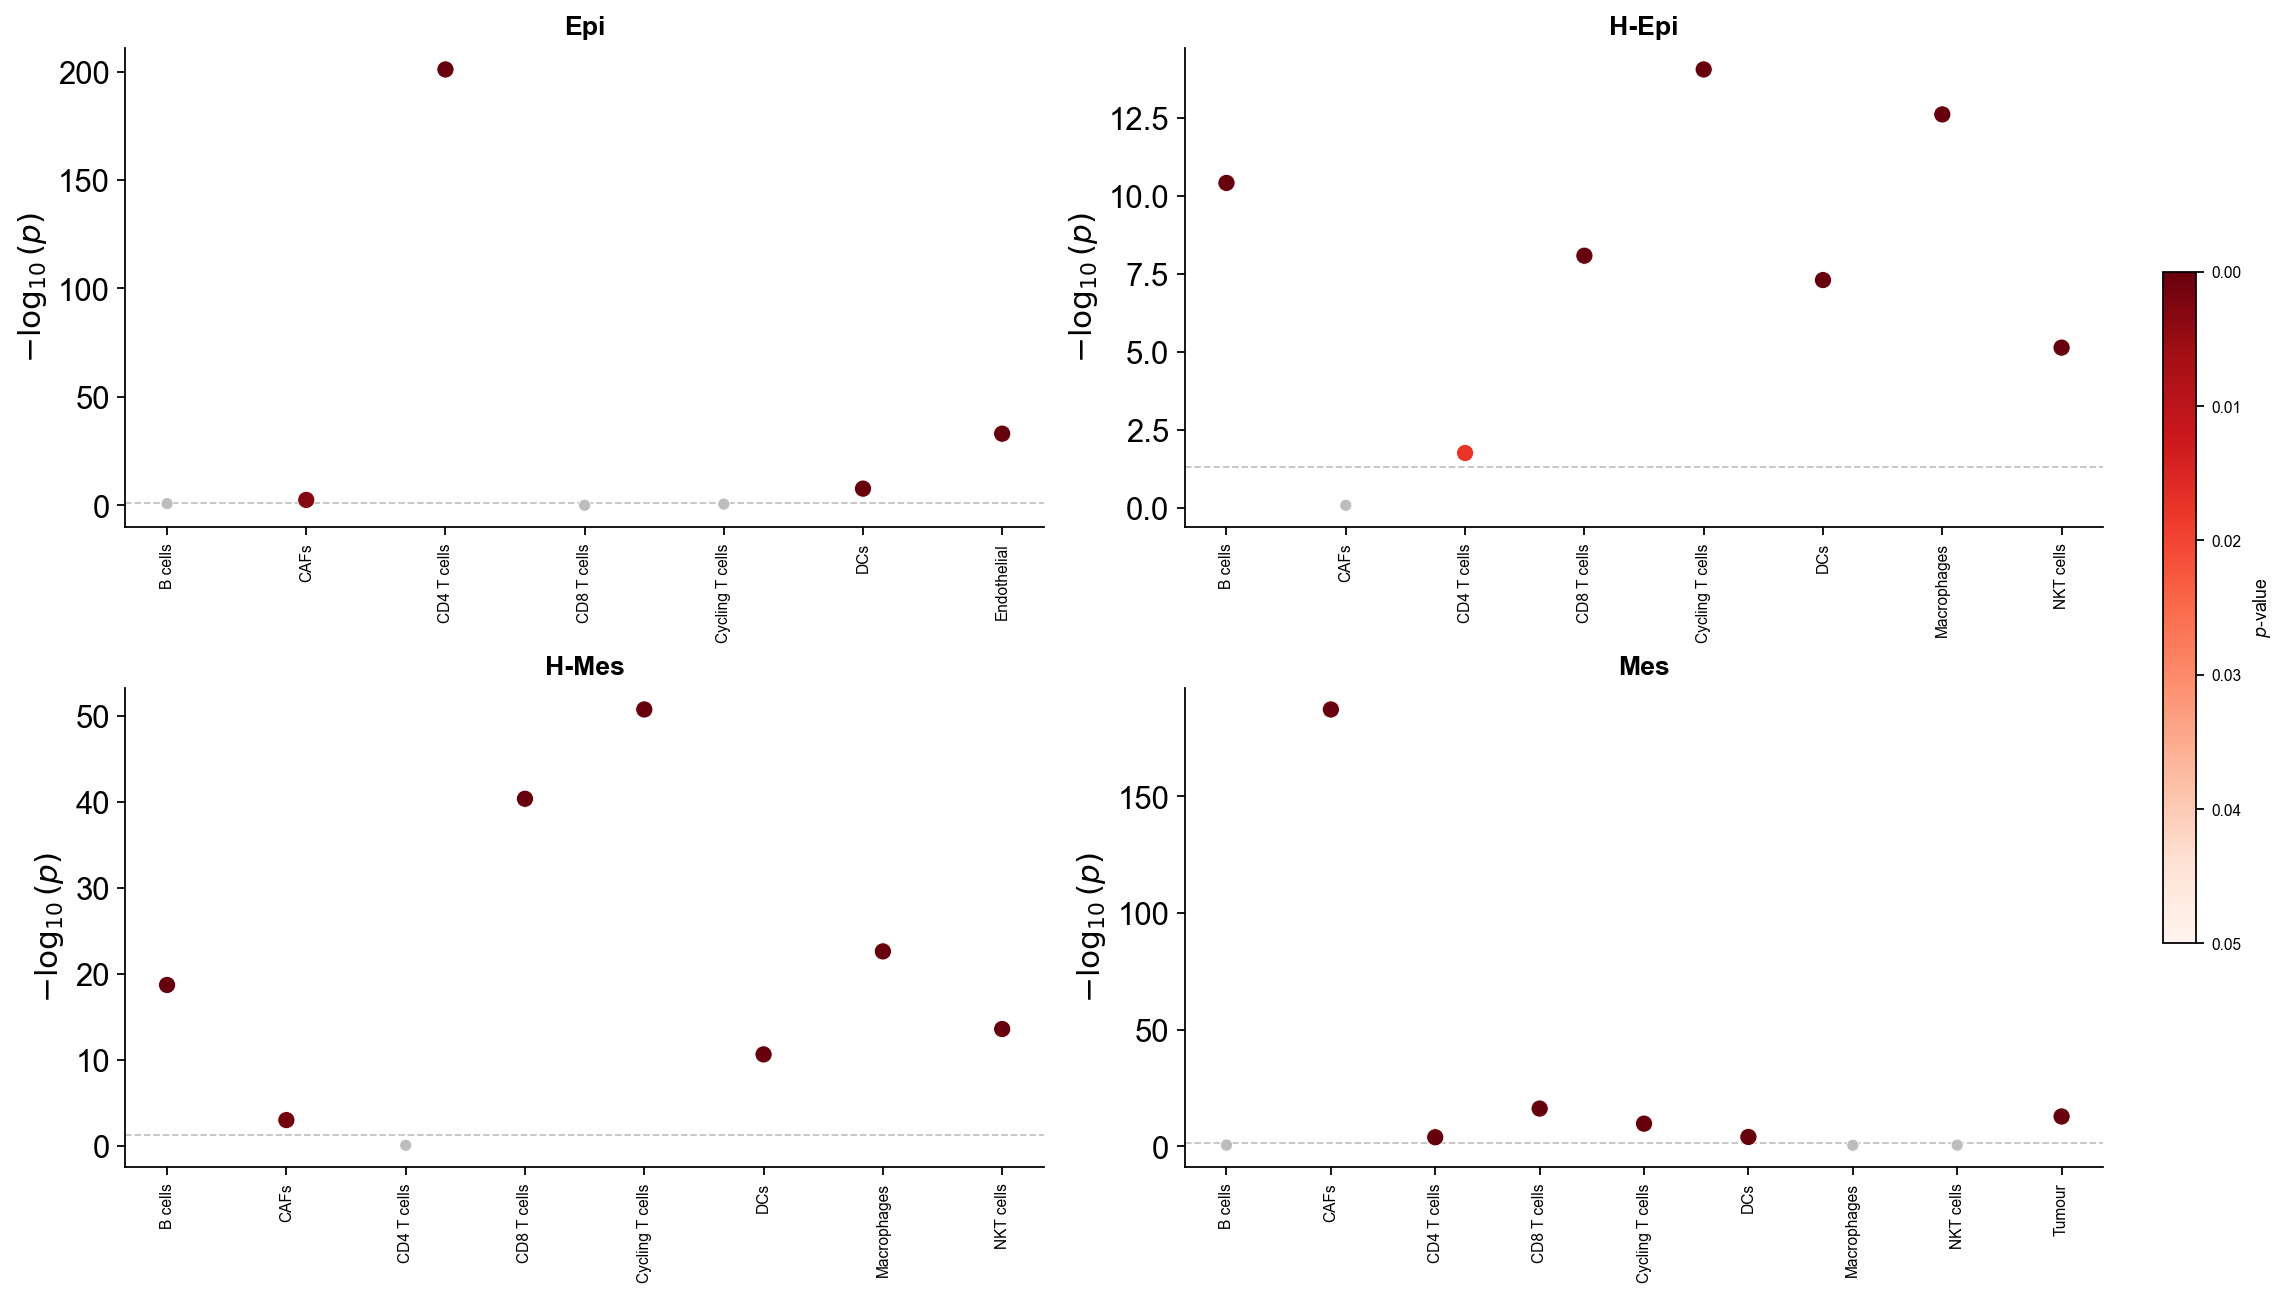

In [11]:
spice.tl.explain_nodes(adata, n_explanations=300)  # increase to 300 for publication quality
spice.pl.node_importance(adata, state_map=EMT_MAP, save=f"figures/simulation_{seed}_node_importance.pdf")